# Stock Simulator
A Monte Carlo simulation of a stock price using NumPy.
Every trading day the price changes by a random percentage drawn from a normal distribution. By repeating the simulation 1000 times, estimate what the price may be in one year, how likely we are to make a profit, and how big the risks are.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(52)

## Simulation parameters

In [2]:
# starting price
start_price = 100

# trading days in a year
days = 252

# average daily growth(0.05%)
mean_return = 0.0005

# how much the price jump(2% per day)
volatility = 0.02

# simulations 1000 days
simulations = 1000

## 1. Random daily returns

Generate a 2D array of random daily returns:
- each row is one scenario
- each column is one trading day

In [3]:
all_returns = np.random.normal(mean_return,volatility, size=(simulations, days))
all_returns

array([[ 0.01088952, -0.02487501,  0.0053084 , ..., -0.04056351,
         0.01683338, -0.00879269],
       [ 0.01380962,  0.02735781,  0.00074899, ...,  0.00915799,
         0.02801154,  0.03256852],
       [ 0.02678967, -0.02325617,  0.00271481, ..., -0.02518542,
         0.00339693, -0.02563556],
       ...,
       [-0.0144607 , -0.02142   ,  0.03105919, ..., -0.01631443,
         0.00120984, -0.00012669],
       [ 0.01194435, -0.02569796,  0.00352221, ...,  0.00335386,
        -0.02285982, -0.00901617],
       [-0.01340673, -0.00305365,  0.00957163, ..., -0.02851636,
        -0.01719828,  0.01779398]], shape=(1000, 252))

## 2. Prices for 1000 scenarios

In [4]:
all_prices = start_price * np.cumprod(1 + all_returns, axis=1)
start_column = np.full((simulations, 1), start_price)
all_prices = np.concatenate((start_column, all_prices), axis=1)
all_prices.shape

(1000, 253)

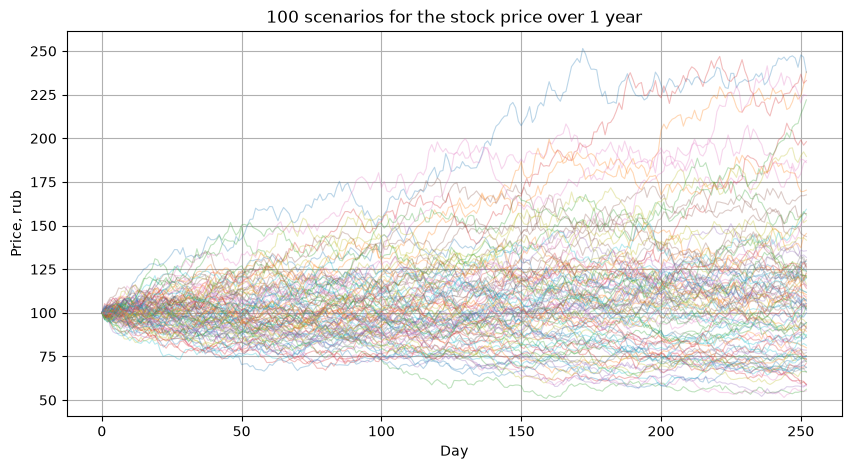

In [5]:
plt.figure(figsize=(10, 5))
plt.plot(all_prices[:100].T, alpha=0.3, linewidth=0.8)
plt.title("100 scenarios for the stock price over 1 year")
plt.xlabel("Day")
plt.ylabel("Price, rub")
plt.grid(True)
plt.show()

## 3. Statistics

The price on the last day of every scenario

In [6]:
final_prices = all_prices[:, -1]

### Mean, median, min and max

In [7]:
average_price = np.round(np.mean(final_prices),3)
median_price = np.round(np.median(final_prices),3)
min_price = np.round(min(final_prices),3)
max_price = np.round(max(final_prices),3)

### Probability of profit

In [8]:
mask = final_prices > start_price
n_above = mask.sum()
share_above = n_above / simulations

### Bad and good realistic outcomes

The minimum and maximum are rare extremes, so percentiles instead:
- 5th percentile: in 95% of scenarios the price will be higher
- 95th percentile: in 95% of scenarios the price will be lower

In [9]:
# in 95% of cases, the price will be above this
worst_case = np.percentile(final_prices, 5)

# in 95% of cases, the price will be below this
best_case = np.percentile(final_prices, 95)

### Distribution of final prices

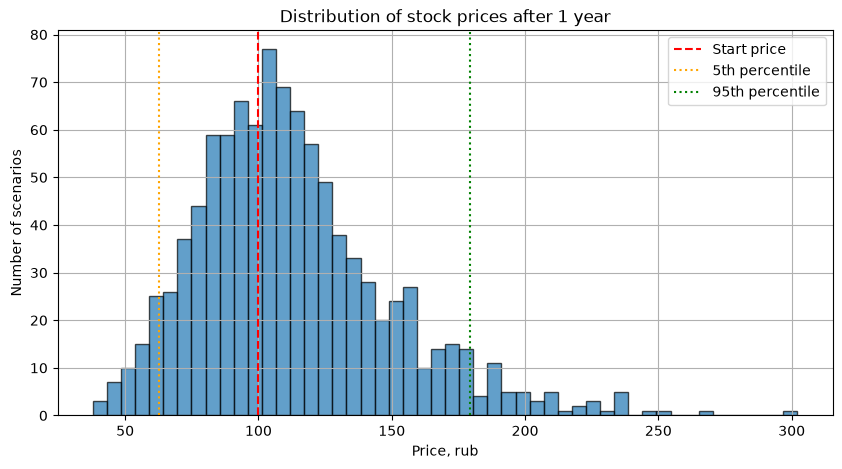

In [10]:
plt.figure(figsize=(10, 5))
plt.hist(final_prices, bins=50, edgecolor="black", alpha=0.7)
plt.axvline(start_price, color="red", linestyle="--", label="Start price")
plt.axvline(worst_case, color="orange", linestyle=":", label="5th percentile")
plt.axvline(best_case, color="green", linestyle=":", label="95th percentile")
plt.title("Distribution of stock prices after 1 year")
plt.xlabel("Price, rub")
plt.ylabel("Number of scenarios")
plt.legend()
plt.grid(True)
plt.show()

### Results

In [11]:
print("Mean price:", average_price)
print("Median price:", median_price)
print("Min price:", min_price)
print("Max price:", max_price)

print(f"Profitable scenarios: {n_above} of {simulations}")
print(f"Probability of profit: {share_above:.1%}")

print("5th percentile:", np.round(worst_case, 2))
print("95th percentile:", np.round(best_case, 2))

Mean price: 112.65
Median price: 107.347
Min price: 37.875
Max price: 302.138
Profitable scenarios: 606 of 1000
Probability of profit: 60.6%
5th percentile: 62.52
95th percentile: 179.43
